<a href="https://colab.research.google.com/github/doddamaniarnavrao/AI_AUTOMATION/blob/main/the_messy_data_dectetive.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [27]:
import pandas as pd
import matplotlib.pyplot as plt
messy = pd.DataFrame({
"name":   ["Riya", "kabir", "Mina", "Leo", "Arnav",
          "Riya", "Kabir", "Mina", "leo", "Arnav", "Arnav"],
"event":  ["Race", "Race", "Race", "Race", "Race",
          "Jump", "Jump", "Jump", "Jump", "Jump", "Jump"],
"points": [8, 6, None, 5, 9, 6, 9, 6, None, 8, 8],
})
print(messy)

     name event  points
0    Riya  Race     8.0
1   kabir  Race     6.0
2    Mina  Race     NaN
3     Leo  Race     5.0
4   Arnav  Race     9.0
5    Riya  Jump     6.0
6   Kabir  Jump     9.0
7    Mina  Jump     6.0
8     leo  Jump     NaN
9   Arnav  Jump     8.0
10  Arnav  Jump     8.0


In [ ]:
# #CLUE 1 · Missing scores
# print(messy.isna().sum()) #name      event     points    0 0 2 dtype: int64 CLUE 2 · A copied row
# print("Duplicate rows:", messy.duplicated().sum()) #Duplicate rows: 1 CLUE 3 ·
# print(messy["name"].unique()) ['Riya' 'kabir' ' Mina' 'Leo''Arnav' 'Kabir' 'Mina' 'leo']

In [28]:
print(messy.groupby("name")["points"].sum())

name
Arnav    25.0
Kabir     9.0
Leo       5.0
Mina      6.0
Riya     14.0
kabir     6.0
leo       0.0
Name: points, dtype: float64


In [29]:
clean = messy.drop_duplicates().copy()
clean["name"] = clean["name"].str.strip().str.title()
clean["points"] = clean["points"].fillna(0)
print(clean)

    name event  points
0   Riya  Race     8.0
1  Kabir  Race     6.0
2   Mina  Race     0.0
3    Leo  Race     5.0
4  Arnav  Race     9.0
5   Riya  Jump     6.0
6  Kabir  Jump     9.0
7   Mina  Jump     6.0
8    Leo  Jump     0.0
9  Arnav  Jump     8.0


name
Arnav    17.0
Kabir    15.0
Riya     14.0
Mina      6.0
Leo       5.0
Name: points, dtype: float64


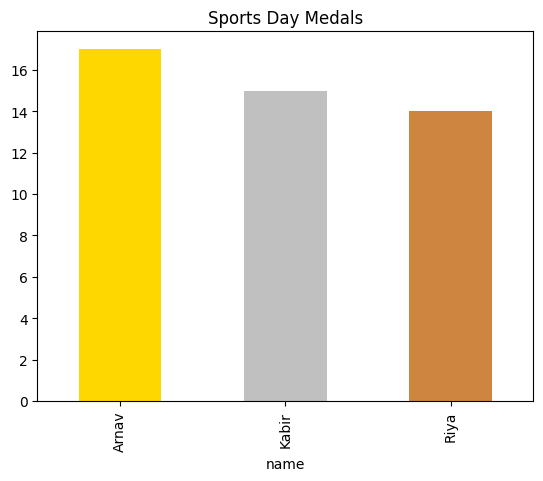

In [24]:
totals = clean.groupby("name")["points"].sum().sort_values(ascending=False)
print(totals)
top3 = totals.head(3)
top3.plot(kind="bar", color=["gold", "silver", "peru"])
plt.title("Sports Day Medals")
plt.show()